**Mapping unemployment data by county**

Import your libraries

In [3]:
%pip install geopandas

  Using cached geopandas-1.2.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached pyogrio-0.13.0-cp311-abi3-macosx_12_0_arm64.whl.metadata (5.8 kB)
  Using cached pyproj-3.8.0-cp314-cp314-macosx_14_0_arm64.whl.metadata (40 kB)
  Using cached shapely-2.2.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (6.7 kB)
Using cached geopandas-1.2.0-py3-none-any.whl (368 kB)
Using cached pyogrio-0.13.0-cp311-abi3-macosx_12_0_arm64.whl (24.7 MB)
Using cached pyproj-3.8.0-cp314-cp314-macosx_14_0_arm64.whl (5.0 MB)
Using cached shapely-2.2.0-cp314-cp314-macosx_11_0_arm64.whl (1.6 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [geopandas]/4 [geopandas]

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import geopandas as gpd
import pandas as pd

Remember the magic command for every notebook

In [5]:
%matplotlib inline

Load up the unemployment data

In [6]:
df = pd.read_csv(
    "../data/unemployment_2018.csv",
    dtype = {
        "state_fips": "object",
        "county_fips": "object",
        "combined_fips": "str"
    }
)

df.head()

,state_fips,county_fips,combined_fips,name,percent_unemployed
0,01,001,01001,"Autauga County, AL",3.6
1,01,003,01003,"Baldwin County, AL",3.6
2,01,005,01005,"Barbour County, AL",5.2
3,01,007,01007,"Bibb County, AL",4.0
4,01,009,01009,"Blount County, AL",3.5


Load up the county map

In [7]:
counties = gpd.read_file(
    "../data/counties.geojson",
    dtype = {
       "GEOID": "object" 
    }
)

counties.head()

/Users/layla/.pyenv/versions/3.14.0/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GeoJSON does not support open option DTYPE
  return ogr_read(


,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,NaN,37340,NaN,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.613, -80.98674 28.61301..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,NaN,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10364 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,NaN,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,NaN,19700,NaN,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,NaN,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [10]:
# Filter to continental USA
counties = counties[
    ~counties["STATEFP"].isin(['72', '60', '66', '69', '78', '02', '15'])
]

Merge

In [13]:
merged = counties.merge(
    df,
    left_on = "GEOID",
    right_on = "combined_fips"
)

merged.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,...,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,state_fips,county_fips,combined_fips,name,percent_unemployed
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,...,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.613, -80.98674 28.61301...",12,009,12009,"Brevard County, FL",3.5
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,...,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10364 38.5...",06,055,06055,"Napa County, CA",2.9
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,...,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787...",18,065,18065,"Henry County, IN",3.5
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,...,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2...",35,029,35029,"Luna County, NM",11.9
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,...,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241...",10,001,10001,"Kent County, DE",4.1


Now plot!

Text(0.5, 1.0, '2018 Unemployment')

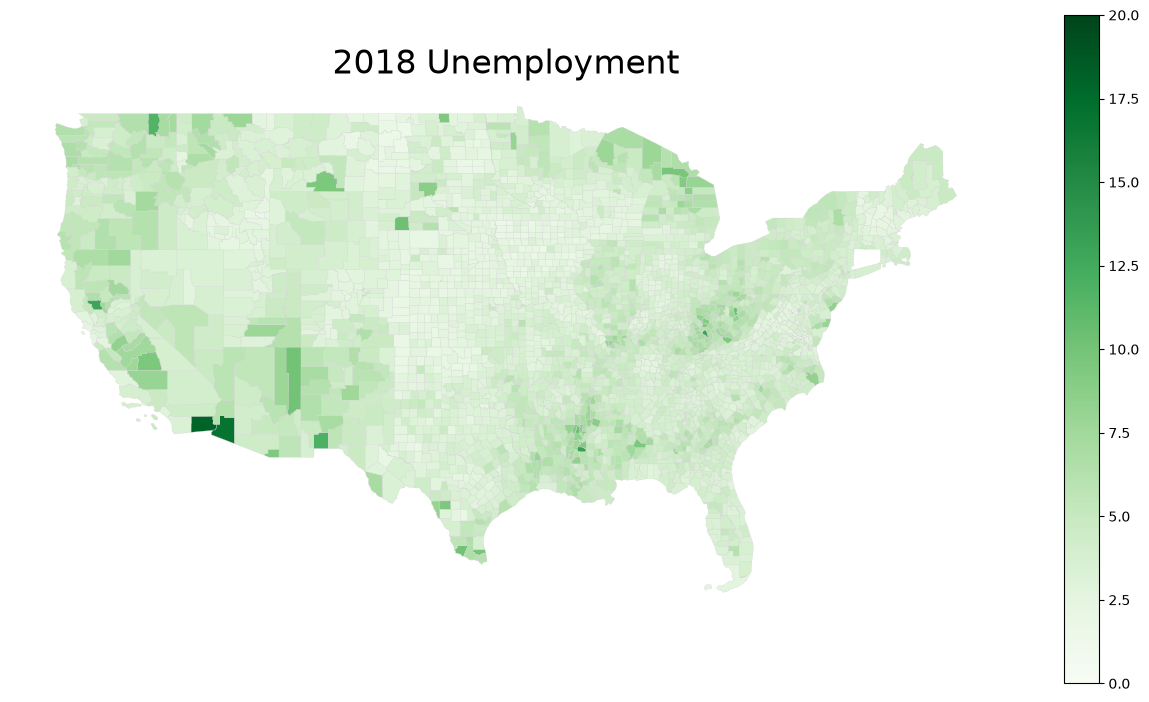

In [14]:
ax = merged.plot(
    column = "percent_unemployed",
    figsize = (16,9),
    cmap = "Greens",
    vmin = 0,
    vmax = 20,
    linewidth = 0.2,
    edgecolor = "lightgray",
    legend = True
)

ax.axis("off")

ax.set_title("2018 Unemployment", fontsize = 24)

Save it as a file

In [7]:
ax.get_figure().savefig("../output/unemployment.png")